**TP3 - Regularización en TNG**

Redes Neuronales en Bioingeniería - ITBA · Franco Perelstein · Entrega: 11/11/2026

Dataset: **20 Newsgroups** (~18.000 posts de Usenet en 20 categorías). El trabajo parte del MLP del TP2 ([repo](https://github.com/francoperelstein/tp2-mlp-20newsgroups)) y del softmax del TP1 ([repo](https://github.com/francoperelstein/tp-softmax-20newsgroups)).


***Objetivos:***
- Incorporar como hiperparámetros posibles la regularización **L1, L2 y L1+L2**, **Dropout** y **BatchNormalization**.
- Para cada técnica, analizar los **valores absolutos de los pesos**, los **tiempos de entrenamiento**, los **valores de learning rate** y el **ruido en las curvas de aprendizaje**, justificando lo observado con lo visto en la clase de Regularización.

***Uso de IA:***
Usé Claude (Anthropic) como asistente para diseñar los experimentos, escribir y depurar código y organizar el análisis.

 **0. Setup**

In [ ]:
!pip install -q mlflow optuna

**1. Datos: 20 Newsgroups**

In [ ]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cuda


In [ ]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:

newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


**2. Preprocesamiento configurable**

In [ ]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)

In [ ]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")

normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


**Análisis:**

El preprocesamiento usa la librería **NLTK** para tres tareas: tokenizar el texto *(word_tokenize)*, sacar palabras que no sirven para discriminar entre clases ya que aparecen en todos los textos *(stopwords.words("english"))* y normalizar cada token con *PorterStemmer* (recorta sufijos con reglas heurísticas) o *WordNetLemmatizer* (busca la forma de diccionario contra la base WordNet).

El pipeline es configurable a propósito: *remove_stopwords* y *normalization* son parámetros de la función, no decisiones fijas. Esto es lo que después Optuna explora como hiperparámetros de preprocesamiento, además de los de entrenamiento.

**3. Vectorización TF-IDF**

In [ ]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [ ]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])

Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


**Análisis:**

La vectorización usa *TfidfVectorizer* de **scikit-learn**. TF-IDF convierte cada documento en un vector donde cada dimensión es un término del vocabulario, ponderado por dos factores: qué tan frecuente es ese término en ese documento (TF) y qué tan poco frecuente es en el total de los documentos (IDF, inverso de la frecuencia en documentos).

El efecto práctico es que términos comunes a casi todos los documentos (como las stopwords) terminan con peso bajo automáticamente, y términos específicos de un tema pesan más. Es importante que el *fit* se haga solo sobre train y el *transform* se aplique igual sobre test. De esta manera, no se filtra información del test al vocabulario aprendido.

**4. Modelo: MLP**


In [ ]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "tanh": nn.Tanh,
    "gelu": nn.GELU,
    "elu": nn.ELU,
    "leaky_relu": nn.LeakyReLU,
}

import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu",
                 dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], input_dim
        for i, h in enumerate(hidden_sizes):
            layers.append(nn.Linear(prev, h, bias=not batchnorm))   # con BN, el beta de BN reemplaza al bias
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))                    # antes de la activación
            layers.append(ACTIVATIONS[activation]())
            es_ultima = (i == len(hidden_sizes) - 1)
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))                 # logits, sin activación
        self.net = nn.Sequential(*layers)
        self.apply(self._init_glorot)

    @staticmethod
    def _init_glorot(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)


@torch.no_grad()
def weight_stats(model, thr=1e-3):
    """|w| medio y fracción de pesos con |w| < thr, solo sobre las matrices de pesos."""
    total, abs_sum, small = 0, 0.0, 0
    for p in model.parameters():
        if p.ndim > 1:
            a = p.abs()
            total += a.numel()
            abs_sum += a.sum().item()
            small += (a < thr).sum().item()
    return abs_sum / total, small / total


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

In [ ]:
def train_model(model, train_loader, val_loader, optimizer, epochs,
                l1=0.0, l2=0.0, max_norm=None, patience=None, trial=None, verbose=False):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    weights = [p for p in model.parameters() if p.ndim > 1]   # solo matrices de pesos: sin bias ni BN
    history = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc",
                               "epoch_time", "w_abs_mean", "w_frac_small"]}
    best_val, wait = float("inf"), 0

    for epoch in range(epochs):
        sync(); t0 = time.perf_counter()

        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            ce = criterion(logits, yb)
            loss = ce
            if l1 > 0:
                loss = loss + l1 * sum(w.abs().sum() for w in weights)
            if l2 > 0:
                loss = loss + l2 * sum((w ** 2).sum() for w in weights)
            loss.backward()
            optimizer.step()
            if max_norm:                                       # max-norm sobre pesos, no bias
                with torch.no_grad():
                    for w in weights:
                        w.renorm_(p=2, dim=0, maxnorm=max_norm)
            run_loss += ce.item() * xb.size(0)                 # se registra solo la CE, sin la penalización
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = run_loss / total, correct / total

        model.eval()
        run_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                run_loss += criterion(logits, yb).item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = run_loss / total, correct / total

        sync(); epoch_time = time.perf_counter() - t0
        w_abs, w_small = weight_stats(model)
        for k, v in zip(history.keys(), [train_loss, val_loss, train_acc, val_acc, epoch_time, w_abs, w_small]):
            history[k].append(v)

        if verbose:
            print(f"Epoch {epoch+1}/{epochs} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - |w|: {w_abs:.4f} - {epoch_time:.2f}s")

        if trial is not None:
            trial.report(val_acc, epoch)
            if not np.isfinite(train_loss) or trial.should_prune():
                trial.set_user_attr("history", history)
                raise optuna.TrialPruned()

        if patience is not None:                               # early stop sobre val_loss
            if val_loss < best_val - 1e-4:
                best_val, wait = val_loss, 0
            else:
                wait += 1
                if wait >= patience:
                    break

    return history

In [ ]:
# Sanity check
x = torch.randn(64, 50, device=device)
for kw in [dict(), dict(dropout=0.3), dict(batchnorm=True), dict(dropout=0.3, batchnorm=True)]:
    m = MLP(50, [32, 16], 20, "relu", **kw).to(device)
    print(kw, "->", " > ".join(type(l).__name__ for l in m.net))
    print("   salida:", tuple(m(x).shape),
          "| pesos regularizables:", sum(p.numel() for p in m.parameters() if p.ndim > 1),
          "| bias/BN sin regularizar:", sum(p.numel() for p in m.parameters() if p.ndim <= 1),
          "| max|w| capa 1: %.3f (Glorot: %.3f)" % (m.net[0].weight.abs().max().item(), (6 / (50 + 32)) ** 0.5))

{} -> Linear > ReLU > Linear > ReLU > Linear
   salida: (64, 20) | pesos regularizables: 2432 | bias/BN sin regularizar: 68 | max|w| capa 1: 0.270 (Glorot: 0.271)
{'dropout': 0.3} -> Linear > ReLU > Dropout > Linear > ReLU > Dropout > Linear
   salida: (64, 20) | pesos regularizables: 2432 | bias/BN sin regularizar: 68 | max|w| capa 1: 0.270 (Glorot: 0.271)
{'batchnorm': True} -> Linear > BatchNorm1d > ReLU > Linear > BatchNorm1d > ReLU > Linear
   salida: (64, 20) | pesos regularizables: 2432 | bias/BN sin regularizar: 116 | max|w| capa 1: 0.270 (Glorot: 0.271)
{'dropout': 0.3, 'batchnorm': True} -> Linear > BatchNorm1d > ReLU > Dropout > Linear > BatchNorm1d > ReLU > Dropout > Linear
   salida: (64, 20) | pesos regularizables: 2432 | bias/BN sin regularizar: 116 | max|w| capa 1: 0.270 (Glorot: 0.271)


In [ ]:
# Sanity check: max-norm
m = MLP(50, [32, 16], 20, "relu", dropout=0.3).to(device)
opt = optim.SGD(m.parameters(), lr=0.1)
xb, yb = torch.randn(64, 50, device=device), torch.randint(0, 20, (64,), device=device)
train_model(m, [(xb, yb)] * 5, [(xb, yb)], opt, epochs=3, max_norm=1.0)
print("norma máxima por neurona:", max(w.norm(dim=1).max().item() for w in m.parameters() if w.ndim > 1))

norma máxima por neurona: 0.9999999403953552


**Análisis:**

El modelo es un MLP configurable en PyTorch: bloques Linear + activación y una Linear final sin activación que devuelve logits (`CrossEntropyLoss` ya incluye el softmax). Las opciones de regularización siguen lo recomendado en los *apuntes de clase*: Dropout después de cada capa oculta *(página 69)*, BatchNorm antes de la activación y con la Linear sin bias, porque el β de BN la reemplaza *(página 81)*, inicialización Glorot uniforme con bias en cero *(páginas 84-85)*. Los sanity checks confirman que el Dropout aparece tras cada capa oculta, que BN elimina el bias y que el max-norm limita la norma por neurona.

Para el loop de entrenamiento se decidió implementarlo a mano. Los términos de L1 y L2 se agregaron a la función de pérdida pero estrictamente sobre las matrices de pesos, sin tocar los bias ni los parámetros de BatchNorm. El max-norm lo aplicamos directamente después de cada paso del optimizador. Para que el registro quede limpio, guardamos la cross-entropy sin la penalización. Medimos los tiempos exactos sincronizando la GPU con time.perf_counter(), y fuimos trackeando el valor medio de los pesos y la fracción de pesos casi nulos (< 1e-3).

**5. Entrenamiento**

In [ ]:
%load_ext tensorboard

In [ ]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

    return history

**Análisis:**

La función `to_tensor_dataset` convierte la matriz TF-IDF en tensores densos que se cargan con `DataLoader`. El entrenamiento final se registra con **MLflow** (parámetros y métricas por época) y **TensorBoard** (curvas de loss y accuracy) en la sección 10.

**6. Búsqueda de hiperparámetros con Optuna**

**Decisiones de diseño:**

- **Estudios por optimizador**: Se armó un estudio separado por cada optimizador (50 intentos cada uno, con su propio pruner).

- **Learning rate (lr)**: Se le dio a cada optimizador su propio rango de lr. Esto fue para evitar que el valor óptimo quede cercano al borde del rango.

- **Regularización**: Probamos L1, L2, ambas juntas o ninguna, buscando el parámetro lambda en escala logarítmica. Esto se lo aplicamos únicamente a las matrices de pesos.

- **BatchNorm y Dropout**: En la búsqueda los hicimos excluyentes (o usábamos uno, o el otro). Para Dropout probamos probabilidades de 0, 0.2, 0.3 y 0.5, acompañándolo con un max-norm de 4 o 5.

- **Corte y objetivo**: Se usó early stopping monitoreando el val_loss con una paciencia de 5 épocas. A Optuna le seteamos que su objetivo final sea maximizar el accuracy de validación, pero sacándolo exactamente de la época donde el val_loss tocó su mínimo.

- **Reproducibilidad**: Para que cada intento se pueda replicar exacto sin importar qué corrió antes, se armó una semilla dinámica a cada trial.

- **Entrada y Test**: Se usó TF-IDF con norma L2, sin estandarización adicional. La clase recomienda estandarizar al usar L1/L2 porque el λ es el mismo para todos los pesos *(página 35 del apunte de clase)*. Esto último no se probó, y queda como limitación de este Trabajo Práctico. El Test no se usa en ningún momento de la búsqueda.

In [ ]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [ ]:
def sample_optimizer_params(trial, name):
    if name == "sgd":
        return {"lr": trial.suggest_float("sgd_lr", 1e-2, 1.0, log=True),
                "momentum": trial.suggest_float("sgd_momentum", 0.0, 0.99)}      # momento de orden 1
    if name == "rmsprop":
        return {"lr": trial.suggest_float("rmsprop_lr", 1e-4, 3e-2, log=True),
                "alpha": trial.suggest_float("rmsprop_alpha", 0.8, 0.999)}        # momento de orden 2
    return {"lr": trial.suggest_float("adam_lr", 1e-4, 3e-2, log=True),
            "beta1": trial.suggest_float("adam_beta1", 0.8, 0.99),
            "beta2": trial.suggest_float("adam_beta2", 0.9, 0.9999)}


def opt_params_from_trial(name, p):
    """Reconstruye los parámetros del optimizador a partir de trial.params."""
    if name == "sgd":
        return {"lr": p["sgd_lr"], "momentum": p["sgd_momentum"]}
    if name == "rmsprop":
        return {"lr": p["rmsprop_lr"], "alpha": p["rmsprop_alpha"]}
    return {"lr": p["adam_lr"], "beta1": p["adam_beta1"], "beta2": p["adam_beta2"]}


def make_optimizer(name, o, parameters):
    if name == "sgd":
        return optim.SGD(parameters, lr=o["lr"], momentum=o["momentum"])
    if name == "rmsprop":
        return optim.RMSprop(parameters, lr=o["lr"], alpha=o["alpha"])
    return optim.Adam(parameters, lr=o["lr"], betas=(o["beta1"], o["beta2"]))

In [ ]:
MAX_EPOCHS = 20
PATIENCE = 5

def objective(trial, opt_name):
    seed = SEED + trial.number
    torch.manual_seed(seed); np.random.seed(seed)
    trial.set_user_attr("optimizer", opt_name)

    # --- HP heredados del TP2 ---
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [5000, 10000, 20000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128, 256])
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden = [trial.suggest_categorical(f"units_l{i+1}", [64, 128, 256, 512, 1024]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS.keys()))

    # --- Regularización (TP3) ---
    reg_type = trial.suggest_categorical("reg_type", ["none", "l1", "l2", "l1_l2"])
    l1 = trial.suggest_float("l1", 1e-9, 1e-4, log=True) if reg_type in ("l1", "l1_l2") else 0.0
    l2 = trial.suggest_float("l2", 1e-7, 1e-2, log=True) if reg_type in ("l2", "l1_l2") else 0.0
    batchnorm = trial.suggest_categorical("batchnorm", [False, True])
    dropout = 0.0 if batchnorm else trial.suggest_categorical("dropout", [0.0, 0.2, 0.3, 0.5])
    max_norm = trial.suggest_categorical("max_norm", [0, 4, 5]) if dropout > 0 else 0
    opt_params = sample_optimizer_params(trial, opt_name)

    # --- Datos: mismo split estratificado y con semilla que en el TP2 ---
    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target)
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_tuple, max_features, min_df)  # fit solo con train
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size,
                              shuffle=True, drop_last=True)                  # drop_last: BN no admite batches de 1
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    # --- Modelo y optimizador ---
    model = MLP(X_tr.shape[1], hidden, NUM_CLASSES, activation, dropout=dropout, batchnorm=batchnorm).to(device)
    optimizer = make_optimizer(opt_name, opt_params, model.parameters())
    trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))
    trial.set_user_attr("config", {
        "optimizer": opt_name, "lr": opt_params["lr"], "reg_type": reg_type, "l1": l1, "l2": l2,
        "dropout": dropout, "batchnorm": batchnorm, "max_norm": max_norm, "n_layers": n_layers,
        "hidden": hidden, "activation": activation, "batch_size": batch_size, "max_features": max_features})

    # --- Entrenamiento ---
    sync(); t0 = time.perf_counter()
    try:
        history = train_model(model, train_loader, val_loader, optimizer, epochs=MAX_EPOCHS,
                              l1=l1, l2=l2, max_norm=max_norm or None, patience=PATIENCE, trial=trial)
    finally:
        sync(); trial.set_user_attr("train_time", time.perf_counter() - t0)

    best_ep = int(np.argmin(history["val_loss"]))          # checkpoint por mínimo de val_loss
    trial.set_user_attr("history", history)
    trial.set_user_attr("best_epoch", best_ep + 1)
    return history["val_acc"][best_ep]

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
_test = optuna.create_study(direction="maximize",
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=1, n_warmup_steps=1))
_test.optimize(lambda t: objective(t, "adam"), n_trials=3, gc_after_trial=True)
for t in _test.trials:
    print(t.number, t.state.name, t.value, f"{t.user_attrs['train_time']:.1f}s", t.user_attrs.get("config"))

0 COMPLETE 0.6955368979231109 16.6s {'optimizer': 'adam', 'lr': 0.0001584688850792548, 'reg_type': 'l1_l2', 'l1': 1.6957266542150105e-06, 'l2': 0.006074318447599173, 'dropout': 0.0, 'batchnorm': True, 'max_norm': 0, 'n_layers': 1, 'hidden': [64], 'activation': 'relu', 'batch_size': 32, 'max_features': 20000}
1 PRUNED 0.6442775077330977 1.9s {'optimizer': 'adam', 'lr': 0.01899628642669488, 'reg_type': 'l1_l2', 'l1': 2.5811060055082435e-08, 'l2': 1.2620069998099132e-05, 'dropout': 0.0, 'batchnorm': True, 'max_norm': 0, 'n_layers': 2, 'hidden': [128, 256], 'activation': 'tanh', 'batch_size': 64, 'max_features': 20000}
2 COMPLETE 0.6999558108705258 5.0s {'optimizer': 'adam', 'lr': 0.007914711681456278, 'reg_type': 'l1', 'l1': 2.83670266983524e-06, 'l2': 0.0, 'dropout': 0.0, 'batchnorm': True, 'max_norm': 0, 'n_layers': 1, 'hidden': [512], 'activation': 'leaky_relu', 'batch_size': 64, 'max_features': 10000}


In [ ]:
OPTIMIZERS = ["adam", "rmsprop", "sgd"]
N_TRIALS_POR_OPT = 50

studies = {}
for name in OPTIMIZERS:
    studies[name] = optuna.create_study(
        study_name=f"tp3_{name}", direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=3),
        storage="sqlite:///optuna_tp3.db", load_if_exists=True)
    faltan = max(0, N_TRIALS_POR_OPT - len(studies[name].trials))
    studies[name].optimize(lambda t, n=name: objective(t, n), n_trials=faltan,
                           gc_after_trial=True, show_progress_bar=True)

for name, s in studies.items():
    comp = [t for t in s.trials if t.state.name == "COMPLETE"]
    print(f"{name:8s} trials={len(s.trials)} completos={len(comp)} podados={len(s.trials) - len(comp)} "
          f"mejor_val_acc={s.best_value:.4f}")

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

adam     trials=50 completos=39 podados=11 mejor_val_acc=0.7508
rmsprop  trials=50 completos=41 podados=9 mejor_val_acc=0.7353
sgd      trials=50 completos=31 podados=19 mejor_val_acc=0.7145


In [ ]:
import pandas as pd

rows = []
for name, s in studies.items():
    for t in s.trials:
        if "config" not in t.user_attrs or "history" not in t.user_attrs:
            continue
        c, h = t.user_attrs["config"], t.user_attrs["history"]
        be = t.user_attrs.get("best_epoch")                    # solo existe en trials completos
        rows.append({
            "optimizer": name, "trial": t.number, "estado": t.state.name, "val_acc": t.value,
            "epocas": len(h["val_acc"]), "best_epoch": be,
            "tiempo_s": t.user_attrs.get("train_time"), "n_params": t.user_attrs.get("n_params"),
            "lr": c["lr"], "reg_type": c["reg_type"], "l1": c["l1"], "l2": c["l2"],
            "dropout": c["dropout"], "batchnorm": c["batchnorm"], "max_norm": c["max_norm"],
            "n_layers": c["n_layers"], "activation": c["activation"],
            "batch_size": c["batch_size"], "max_features": c["max_features"],
            "w_abs_best": h["w_abs_mean"][be - 1] if be else None,
            "gap_acc_best": (h["train_acc"][be - 1] - h["val_acc"][be - 1]) if be else None,
        })
df3 = pd.DataFrame(rows)

def familia(r):
    partes = []
    if r["l1"] >= 1e-7: partes.append("l1")      # por debajo, la penalización es <1% de la CE
    if r["l2"] >= 1e-6: partes.append("l2")
    if r["dropout"] > 0: partes.append("dropout")
    if r["batchnorm"]: partes.append("bn")
    return "+".join(partes) or "sin_reg"
df3["familia"] = df3.apply(familia, axis=1)
done = df3[df3["estado"] == "COMPLETE"]

print("--- tiempo total de reloj por estudio ---")
for name, s in studies.items():
    t0 = min(t.datetime_start for t in s.trials); t1 = max(t.datetime_complete for t in s.trials)
    print(f"{name:8s} {t1 - t0}")

print("\n--- top 10 (completos) ---")
cols = ["optimizer", "trial", "val_acc", "best_epoch", "tiempo_s", "n_params", "lr", "familia",
        "l1", "l2", "dropout", "max_norm", "n_layers", "activation", "batch_size", "max_features"]
print(done.sort_values("val_acc", ascending=False).head(10)[cols].round(5).to_string(index=False))

def resumen(col):
    g = df3.groupby(col).agg(trials=("trial", "count"), podados=("estado", lambda s: (s == "PRUNED").sum()))
    d = done.groupby(col).agg(val_acc_media=("val_acc", "mean"), val_acc_max=("val_acc", "max"),
                              tiempo_mediano_s=("tiempo_s", "median"), epoca_mediana=("best_epoch", "median"),
                              lr_mediano=("lr", "median"), w_abs_mediano=("w_abs_best", "median"))
    return g.join(d).round(4)

for col in ["optimizer", "familia", "reg_type", "batchnorm", "dropout", "n_layers", "activation", "batch_size", "max_features"]:
    print(f"\n--- por {col} ---"); print(resumen(col).to_string())

print("\n--- importancia de hiperparámetros (Optuna; los condicionales aplican a pocos trials) ---")
for name, s in studies.items():
    try:
        imp = optuna.importance.get_param_importances(s)
        print(name, {k: round(v, 3) for k, v in list(imp.items())[:8]})
    except Exception as e:
        print(name, "no disponible:", str(e)[:80])

--- tiempo total de reloj por estudio ---
adam     0:07:12.889467
rmsprop  0:08:38.589482
sgd      0:09:58.756110

--- top 10 (completos) ---
optimizer  trial  val_acc  best_epoch  tiempo_s  n_params      lr    familia  l1  l2  dropout  max_norm  n_layers activation  batch_size  max_features
     adam     41  0.75077         6.0   7.43949   1494036 0.00166    dropout 0.0 0.0      0.5         0         1 leaky_relu          64         20000
     adam     34  0.74680        16.0  13.30285   1494036 0.00056    dropout 0.0 0.0      0.5         0         1 leaky_relu          64         20000
     adam     49  0.74503         2.0   4.71795   2988052 0.00172    sin_reg 0.0 0.0      0.0         0         1        elu          64         20000
     adam     44  0.74459         4.0   6.29135   2988052 0.00203    dropout 0.0 0.0      0.5         0         1 leaky_relu          64         20000
     adam     43  0.74370         3.0   5.13780   1494036 0.00328    dropout 0.0 0.0      0.5         0

In [ ]:
top = done.sort_values("val_acc", ascending=False).head(10)
print(top[["optimizer", "trial", "val_acc", "familia", "l1", "l2", "dropout", "max_norm"]]
      .to_string(formatters={"l1": "{:.1e}".format, "l2": "{:.1e}".format}, index=False))

print("\n--- lr mediano y |w| mediano DENTRO de cada optimizador ---")
done = done.assign(con_dropout=done["dropout"] > 0)
for col in ["batchnorm", "con_dropout", "reg_type"]:
    print(f"\npor optimizer x {col}")
    print(done.groupby(["optimizer", col]).agg(n=("trial", "count"), val_acc_mediana=("val_acc", "median"),
          lr_mediano=("lr", "median"), w_abs_mediano=("w_abs_best", "median"),
          epoca_mediana=("best_epoch", "median")).round(4).to_string())

optimizer  trial  val_acc    familia      l1      l2  dropout  max_norm
     adam     41 0.750773    dropout 2.5e-09 0.0e+00      0.5         0
     adam     34 0.746796    dropout 2.8e-09 0.0e+00      0.5         0
     adam     49 0.745029    sin_reg 1.2e-09 0.0e+00      0.0         0
     adam     44 0.744587    dropout 6.8e-09 0.0e+00      0.5         0
     adam     43 0.743703    dropout 5.7e-09 0.0e+00      0.5         0
     adam     47 0.742377    sin_reg 2.6e-09 0.0e+00      0.0         0
     adam     45 0.741935    dropout 5.9e-09 0.0e+00      0.5         4
     adam     30 0.741494 l2+dropout 0.0e+00 1.8e-06      0.5         0
     adam     27 0.741052 l2+dropout 0.0e+00 2.0e-06      0.5         0
     adam     29 0.740610 l2+dropout 0.0e+00 2.7e-06      0.5         0

--- lr mediano y |w| mediano DENTRO de cada optimizador ---

por optimizer x batchnorm
                      n  val_acc_mediana  lr_mediano  w_abs_mediano  epoca_mediana
optimizer batchnorm                  

**Análisis:**

- **Resultados generales de la búsqueda**: Se corrieron 150 trials (50 por optimizador) en  26 minutos (7:13 con Adam, 8:39 con RMSprop y 9:59 con SGD), donde 39 se podaron (11, 9 y 19, respectivamente). El mejor trial (val_acc 0.7508) es de Adam, con 1 capa de 128 neuronas, leaky_relu, batch 64, lr 0.00166, Dropout 0.5 y 11.651 features reales (el tope de 20.000 no fue limitante). Su λ de L1 es 2.5e-9, que no regulariza. Los 10 mejores trials están entre 0.741 y 0.751 y todos tienen λ de L1 ≤ 7e-9 o de L2 ≤ 3e-6; con ~2.263 documentos de validación el error de un accuracy es de ~0.9 puntos, así que no se pueden ordenar entre sí.

- **Patrones principales**: Usar una sola capa (promedio 0.710) rinde más que usar dos (0.660) o tres (0.544). Por otro lado, SGD fue el peor optimizador de todos (su máximo fue 0.7145) y necesitó que le demos un learning rate 12 veces mayor que Adam y 16 veces mayor que RMSprop para funcionar. Por último, los batches grandes son más rápidos (mediana de 3.4 s con batch 128 y 7.6 s con batch 32). El pruning descartó el 22% de los trials de Adam (11 de 50), el 18% de los de RMSprop (9 de 50) y el 38% de los de SGD (19 de 50). No comprobé si alguno de los podados habría terminado mejor, por lo que la búsqueda pudo perder configuraciones que arrancan lento, sobre todo con SGD.

- **El problema de comparar en la búsqueda**: Esta etapa de Optuna no sirvió para comparar técnicas limpiamente. Como el algoritmo TPE es inteligente, se concentró solo en lo que daba resultado y marginó al resto. Respecto a esto último, se puede ver que, por ejemplo, la configuración sin regularizar la probó solo 6 veces (y podó 3). Por otro lado, en este trabajo práctico no se pudo comprobar que usar BatchNorm permita subir el lr. *Por todo lo expuesto en esta sección, la verdadera comparación de técnicas la tuvimos que hacer a mano en la sección 7 con los experimentos controlados.*

**7. Experimentos controlados**

Toman la mejor configuración de Adam como base, la entrenan sin regularización como referencia y cambian un factor por vez, con 5 semillas, 30 épocas en el A y 40 en el B, sin parar antes, para ver toda la dinámica. Elegimos el epoch del mínimo de val_loss después, desde el historial.

In [ ]:
BASE_TRIAL = studies["adam"].best_trial
bp = BASE_TRIAL.params
print("Config base (mejor trial de Adam):", bp)

BASE = dict(
    remove_stopwords=bp["remove_stopwords"], normalization=bp["normalization"],
    ngram=(1, 1) if bp["ngram_range"] == "1gram" else (1, 2),
    max_features=bp["max_features"], min_df=bp["min_df"],
    hidden=[bp[f"units_l{i+1}"] for i in range(bp["n_layers"])],
    activation=bp["activation"], batch_size=bp["batch_size"],
    lr=bp["adam_lr"], betas=(bp["adam_beta1"], bp["adam_beta2"]),
    l1=0.0, l2=0.0, dropout=0.0, batchnorm=False, max_norm=0)

txt_tr, _ = preprocessed_cache[(BASE["remove_stopwords"], BASE["normalization"])]
a, b, ya, yb = train_test_split(txt_tr, newsgroups_train.target, test_size=0.2,
                                random_state=SEED, stratify=newsgroups_train.target)
X_a, X_b, _ = vectorize_data(a, b, BASE["ngram"], BASE["max_features"], BASE["min_df"])  # fit solo con train
DS_TR, DS_VA = to_tensor_dataset(X_a, ya), to_tensor_dataset(X_b, yb)
N_FEATURES = X_a.shape[1]
print("n_features reales:", N_FEATURES)

Config base (mejor trial de Adam): {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 5, 'batch_size': 64, 'n_layers': 1, 'units_l1': 128, 'activation': 'leaky_relu', 'reg_type': 'l1', 'l1': 2.5311454539337423e-09, 'batchnorm': False, 'dropout': 0.5, 'max_norm': 0, 'adam_lr': 0.0016587527272262502, 'adam_beta1': 0.9214521805966703, 'adam_beta2': 0.9577115551375311}
n_features reales: 11651


In [ ]:
def noise(x, start=4, win=5):
    """Ruido = desvío del residuo respecto de una media móvil centrada (ignora la tendencia)."""
    x = np.asarray(x[start:], dtype=float)
    if len(x) < win + 2:
        return float("nan")
    trend = np.convolve(x, np.ones(win) / win, mode="valid")
    resid = x[win // 2: len(x) - win // 2] - trend
    return float(np.std(resid))

RESULTS = {}

def run_experiment(name, seeds=range(5), epochs=30, **overrides):
    cfg = {**BASE, **overrides}
    runs = []
    for s in seeds:
        torch.manual_seed(1000 + s); np.random.seed(1000 + s)
        tl = DataLoader(DS_TR, batch_size=cfg["batch_size"], shuffle=True, drop_last=True)
        vl = DataLoader(DS_VA, batch_size=cfg["batch_size"], shuffle=False)
        model = MLP(N_FEATURES, cfg["hidden"], NUM_CLASSES, cfg["activation"],
                    dropout=cfg["dropout"], batchnorm=cfg["batchnorm"]).to(device)
        opt = optim.Adam(model.parameters(), lr=cfg["lr"], betas=cfg["betas"])
        h = train_model(model, tl, vl, opt, epochs=epochs, l1=cfg["l1"], l2=cfg["l2"],
                        max_norm=cfg["max_norm"] or None)
        w1 = model.net[0].weight.detach().cpu().numpy().ravel() if s == seeds[0] else None
        runs.append({"history": h, "w_first_layer": w1})
        del model, opt
    RESULTS[name] = {"cfg": cfg, "runs": runs}

def summarize(names=None):
    rows = []
    for name, r in RESULTS.items():
        if names and name not in names:
            continue
        acc, ep, tb, wa, ws, ntr, nva, gap = [], [], [], [], [], [], [], []
        for run in r["runs"]:
            h = run["history"]; be = int(np.argmin(h["val_loss"]))      # mejor época por val_loss
            acc.append(h["val_acc"][be]); ep.append(be + 1); tb.append(sum(h["epoch_time"][:be + 1]))
            wa.append(h["w_abs_mean"][be]); ws.append(h["w_frac_small"][-1])
            ntr.append(noise(h["train_acc"])); nva.append(noise(h["val_acc"]))
            gap.append(h["train_acc"][be] - h["val_acc"][be])
        n = len(acc)
        rows.append({"config": name, "val_acc": np.mean(acc), "EE": np.std(acc, ddof=1) / np.sqrt(n),
                     "epoca_mejor": np.median(ep), "t_hasta_mejor_s": np.mean(tb), "|w|_mejor": np.mean(wa),
                     "frac<1e-3_final": np.mean(ws), "ruido_train": np.mean(ntr), "ruido_val": np.mean(nva),
                     "gap_acc": np.mean(gap)})
    return pd.DataFrame(rows).round(4)

**Experimento A:** L1, L2 y L1+L2

In [ ]:
run_experiment("ref (sin reg)")
for lam in [1e-5, 1e-4, 1e-3]:
    run_experiment(f"L2 {lam:.0e}", l2=lam)
for lam in [1e-6, 1e-5, 1e-4]:
    run_experiment(f"L1 {lam:.0e}", l1=lam)
run_experiment("L1 1e-5 + L2 1e-4", l1=1e-5, l2=1e-4)
print(summarize().to_string(index=False))

           config  val_acc     EE  epoca_mejor  t_hasta_mejor_s  |w|_mejor  frac<1e-3_final  ruido_train  ruido_val  gap_acc
    ref (sin reg)   0.7445 0.0009          4.0           2.2101     0.0620           0.0031       0.0007     0.0020   0.1852
         L2 1e-05   0.7387 0.0011          4.0           2.4638     0.0430           0.0846       0.0009     0.0022   0.1865
         L2 1e-04   0.7236 0.0017          5.0           3.1715     0.0245           0.0971       0.0013     0.0027   0.1925
         L2 1e-03   0.7033 0.0024         28.0          16.9350     0.0106           0.1491       0.0022     0.0046   0.0758
         L1 1e-06   0.7378 0.0008          4.0           2.4396     0.0402           0.4150       0.0009     0.0021   0.1852
         L1 1e-05   0.7198 0.0020          5.0           2.9726     0.0190           0.4774       0.0013     0.0023   0.1684
         L1 1e-04   0.6649 0.0014         30.0          17.8205     0.0051           0.6525       0.0016     0.0029   0.1730


**Análisis:**

El modelo base llegó a un accuracy de 0.7445 (± 0.0009) en la época 4. Lo más llamativo de aplicar regularización fue que subir el lambda (λ) siempre nos empeoró el resultado: la caída es constante tanto para L1 como para L2, y las diferencias son significativas.

Por otro lado, con lambdas altos (L2 1e-3 y L1 1e-4) el modelo no termina de converger: su mejor época fue la 28 o 30, pegando contra el límite de épocas que le pusimos, por lo que ese resultado es solo una cota inferior. Lo que sí hace bien la regularización es "controlar" la curva del val_loss a largo plazo y evitar que crezca tanto como en el modelo sin regularizar, pero al final del proyecto no nos sirvió para subir el pico de accuracy.

Estos resultados son coherentes con la clase, ya que L2 mantiene los pesos chicos y L1 produce matrices esparsas (*páginas 52 y 58 de la clase)*, pero a mayor λ el modelo pierde capacidad de ajuste. El documento de la clase propone λ ≈ 1e-4 para L2 *(página 52)*, pero en nuestros ensayos ese valor cuesta ~2 puntos (0.7236 contra 0.7445).

**Experimento B:** Dropout, max-norm y BatchNorm

In [ ]:
E = 40
run_experiment("ref (40 ep)", epochs=E)
run_experiment("dropout 0.2", epochs=E, dropout=0.2)
run_experiment("dropout 0.5", epochs=E, dropout=0.5)
run_experiment("dropout 0.5 + maxnorm 4", epochs=E, dropout=0.5, max_norm=4)
for mult in [3, 10]:
    run_experiment(f"dropout 0.5, lr x{mult}", epochs=E, dropout=0.5, lr=BASE["lr"] * mult)
run_experiment("ref, lr x10", epochs=E, lr=BASE["lr"] * 10)
run_experiment("BN", epochs=E, batchnorm=True)
run_experiment("BN, lr x10", epochs=E, batchnorm=True, lr=BASE["lr"] * 10)
run_experiment("BN + dropout 0.5", epochs=E, batchnorm=True, dropout=0.5)
run_experiment("BN, batch 32", epochs=E, batchnorm=True, batch_size=32)
run_experiment("BN, batch 256", epochs=E, batchnorm=True, batch_size=256)

B_NAMES = ["ref (40 ep)", "dropout 0.2", "dropout 0.5", "dropout 0.5 + maxnorm 4", "dropout 0.5, lr x3",
           "dropout 0.5, lr x10", "ref, lr x10", "BN", "BN, lr x10", "BN + dropout 0.5", "BN, batch 32", "BN, batch 256"]
print(summarize(B_NAMES).to_string(index=False))

                 config  val_acc     EE  epoca_mejor  t_hasta_mejor_s  |w|_mejor  frac<1e-3_final  ruido_train  ruido_val  gap_acc
            ref (40 ep)   0.7445 0.0009          4.0           2.2408     0.0620           0.0030       0.0007     0.0021   0.1852
            dropout 0.2   0.7441 0.0010          5.0           2.7747     0.0638           0.0033       0.0010     0.0019   0.1833
            dropout 0.5   0.7464 0.0010          6.0           3.5503     0.0625           0.0041       0.0013     0.0017   0.1577
dropout 0.5 + maxnorm 4   0.7426 0.0016          4.0           2.4269     0.0295           0.0211       0.0024     0.0025   0.0667
     dropout 0.5, lr x3   0.7419 0.0018          2.0           1.2777     0.0725           0.0030       0.0006     0.0021   0.0819
    dropout 0.5, lr x10   0.7327 0.0019          1.0           0.5683     0.1318           0.0017       0.0006     0.0031  -0.1478
            ref, lr x10   0.7244 0.0026          1.0           0.5925     0.1449   

**Análisis:**

- **Dropout y max-norm**: Ninguna técnica mejoró realmente el pico de accuracy (0.743-0.746 en la época de mínimo val_loss, y 0.748-0.749 si se toma el máximo de val_acc). La ventaja real se ve a largo plazo: en la época 40 el modelo base decae bastante, pero combinando Dropout 0.5 y max-norm 4, el modelo retiene un accuracy de 0.743 y frena la subida del val_loss. Confirmamos en la práctica la *página 75 del documento de clase* (mayor estabilidad) y vimos cómo max-norm acota físicamente los pesos a 4.0 para frenar el overfitting en el set de entrenamiento. Si se usaba solo Dropout 0.5, la mejora era mínima, pero como era de esperarse, nos "pateaba" el mejor resultado para más adelante (de la época 4 a la 6) porque necesita más tiempo de aprendizaje *(página 68 de la clase)*.

- **Learning rate**: Si subimos el lr (×3 o ×10), el modelo converge demasiado rápido (época 1 o 2) hacia un resultado peor y sobreajusta de entrada, aunque Dropout ayuda a que la caída no sea tan grave. La clase recomienda multiplicar el lr bastante al usar Dropout *(página 69)*.

- **BatchNorm**: Con BatchNorm el modelo sobreajusta rapidísimo, ya que toca su máximo en la época 1 y después se desploma. Respecto al tamaño de batch, según el máximo de val_acc subir el batch a 256 mejora de 0.719 a 0.728, pero con el criterio de mínimo val_loss no hay diferencia (0.7175 contra 0.7185). Esto es compatible con lo que sugiere la *página 78 del documento de clase*, donde cuando tenemos batches chicos, las estadísticas de BN son más ruidosas. Finalmente, se probó combinar BatchNorm con Dropout 0.5 y los resultados fueron casi los mismos que con BatchNorm solo, así que no se pudo confirmar el daño por usarlos juntos que menciona la *página 81 del documento de clase*.


Se deja mencionado que los valores de este apartado son aproximados leídos de las curvas.

**Curvas por grupo:**

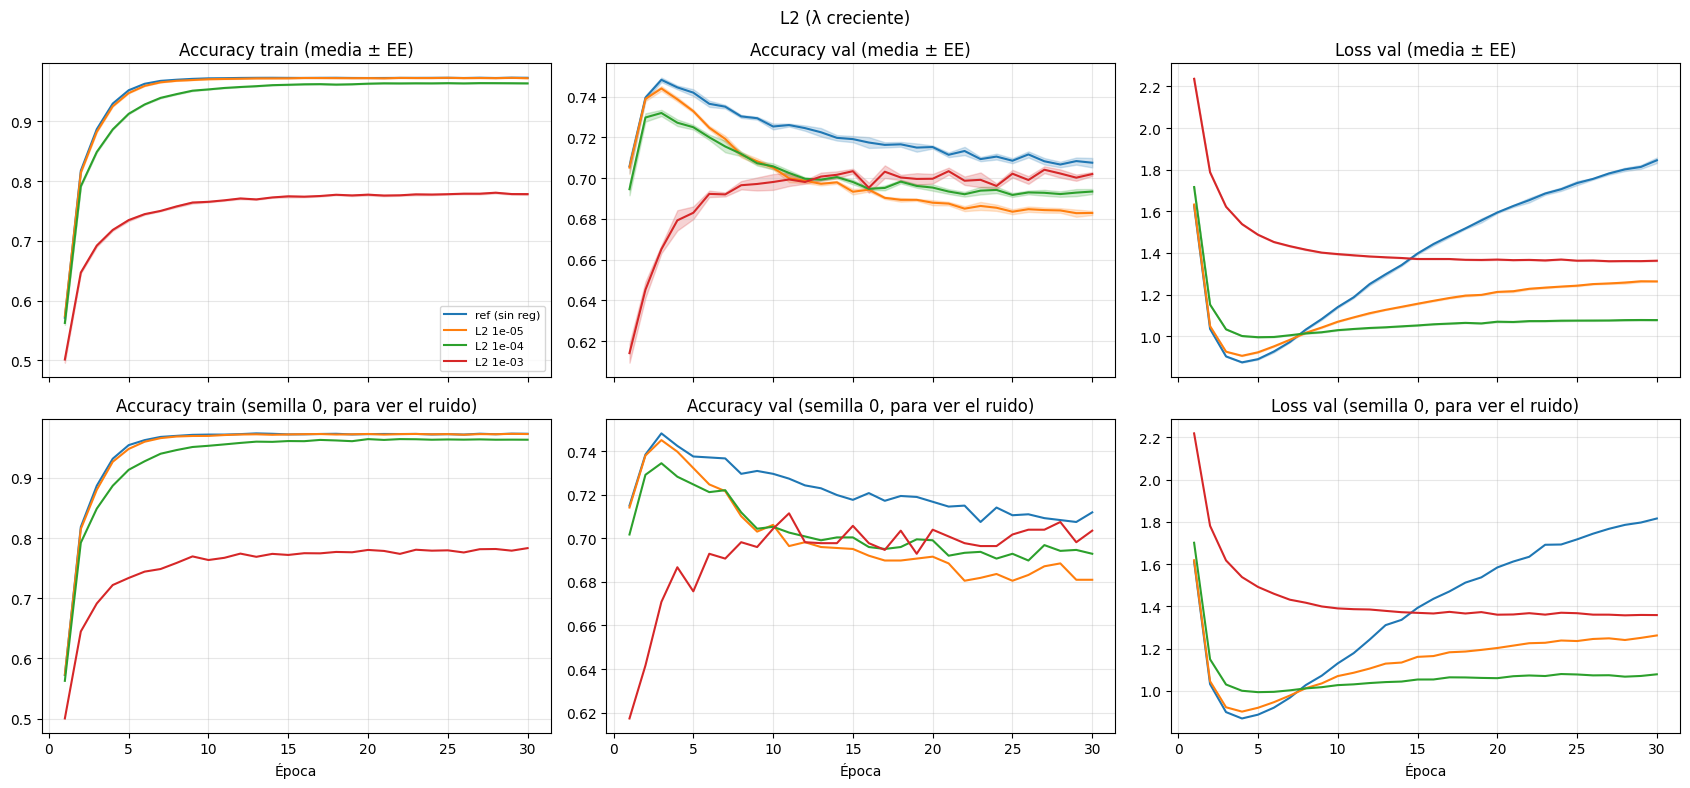

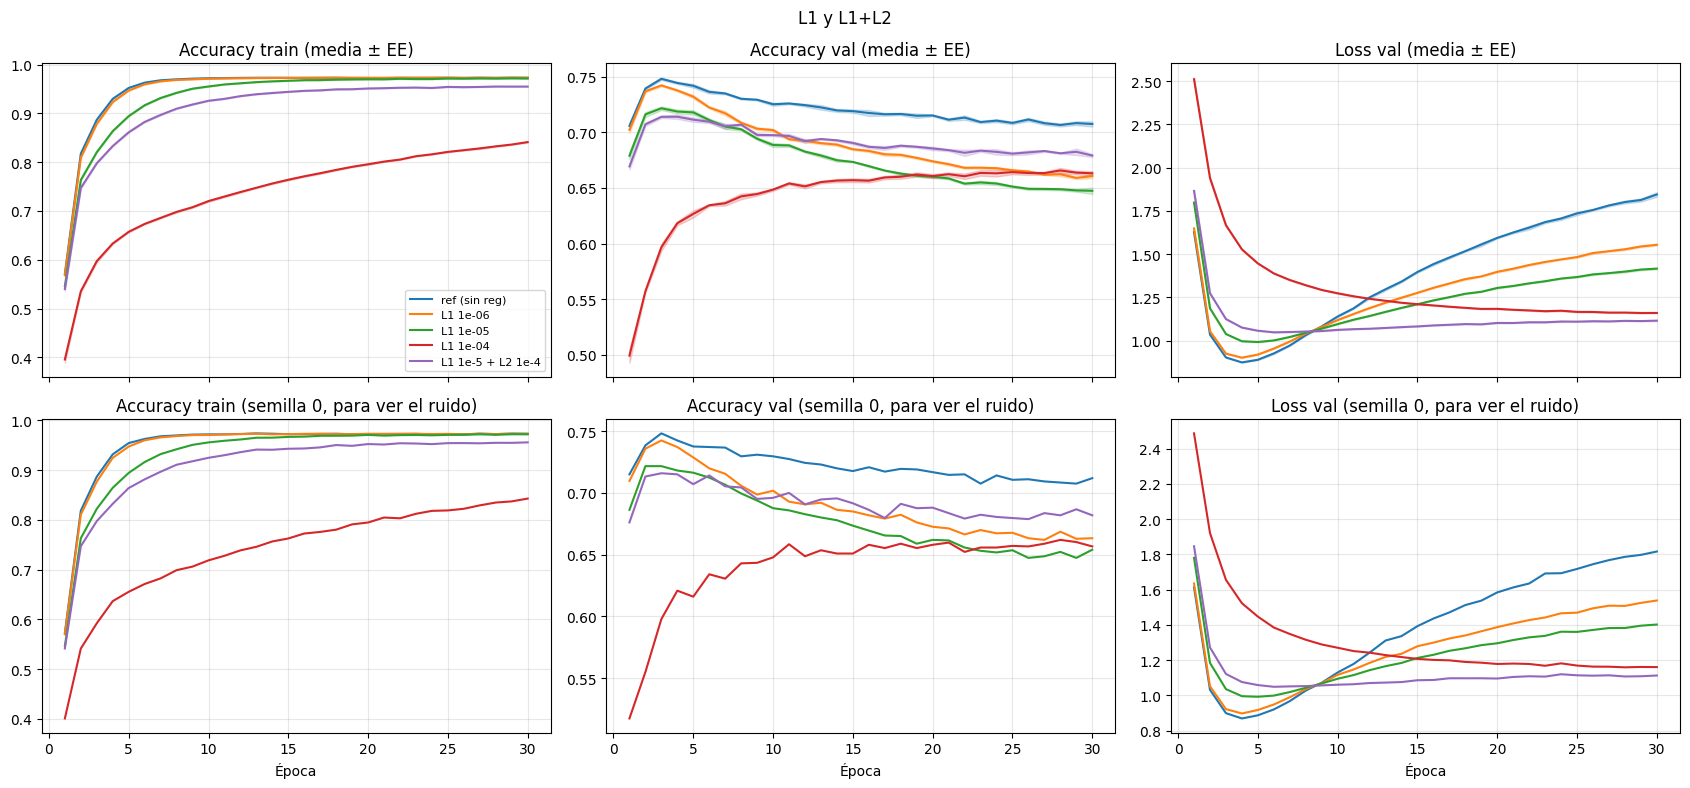

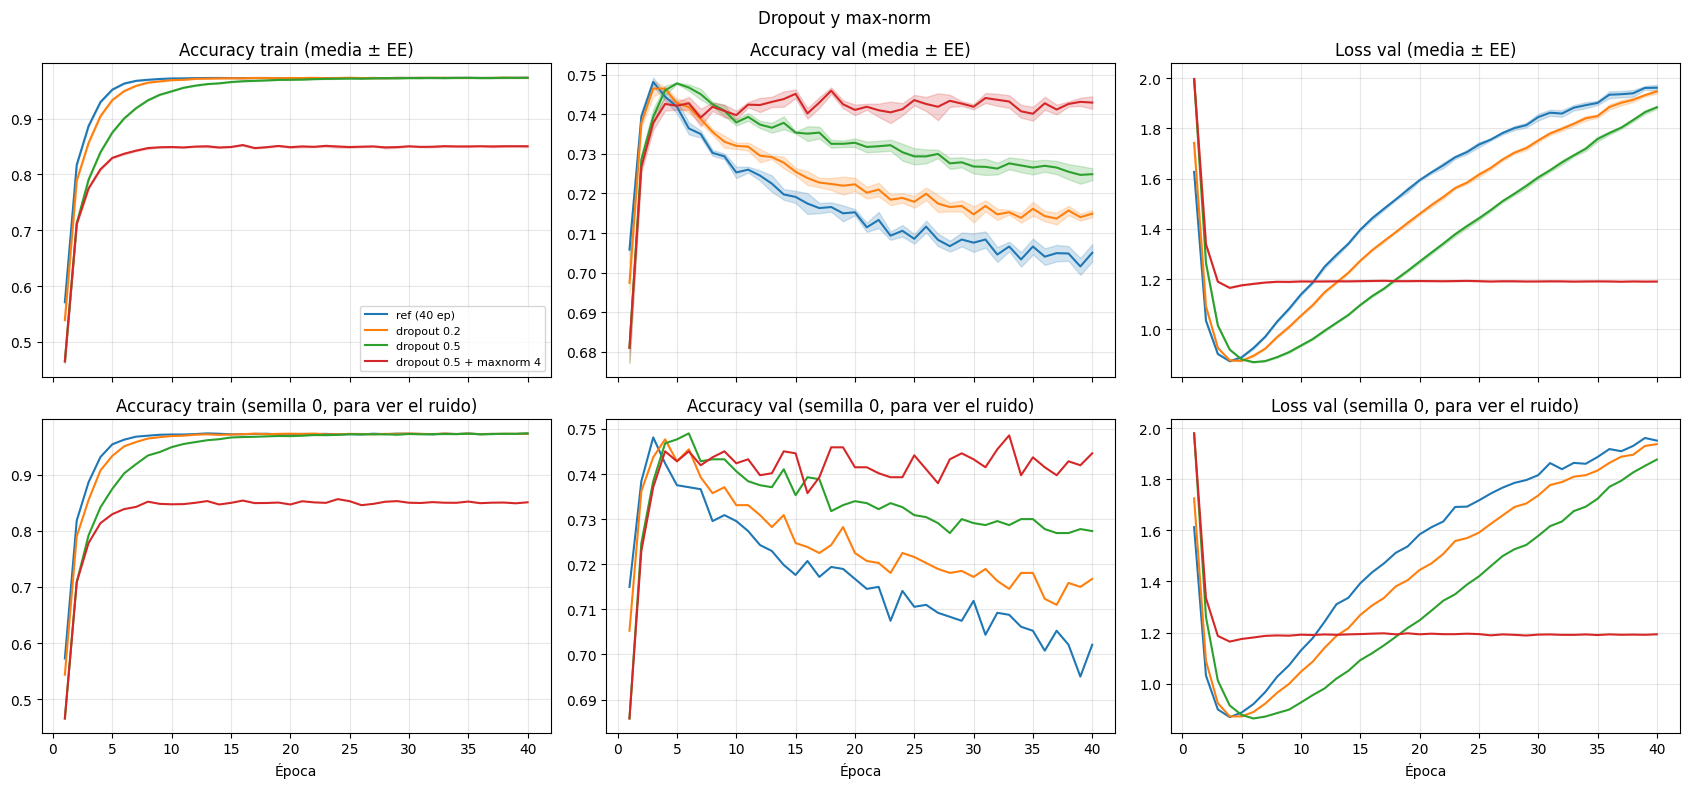

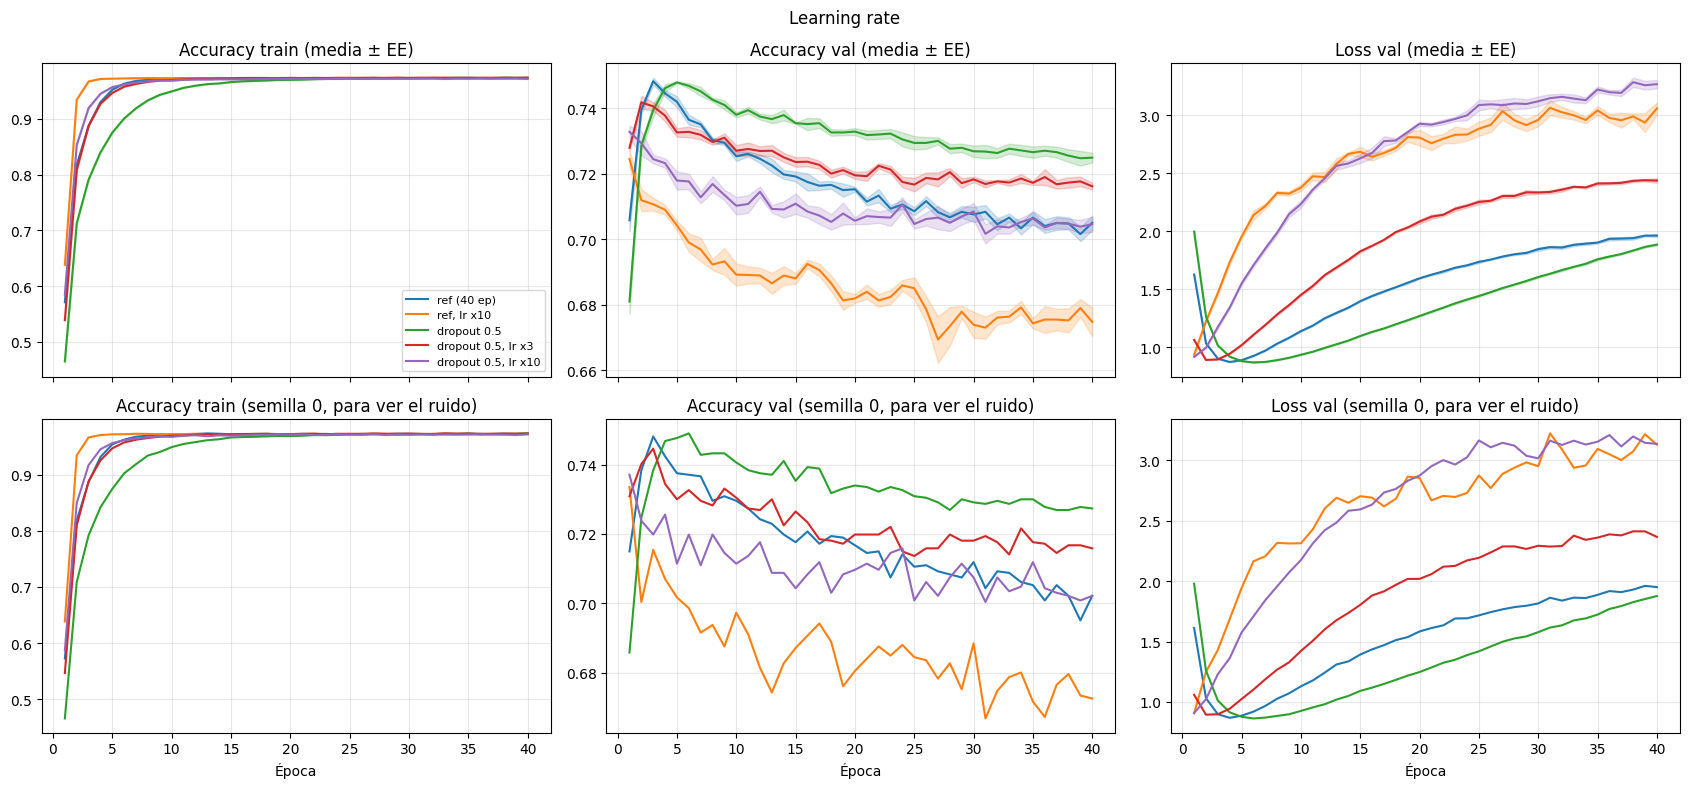

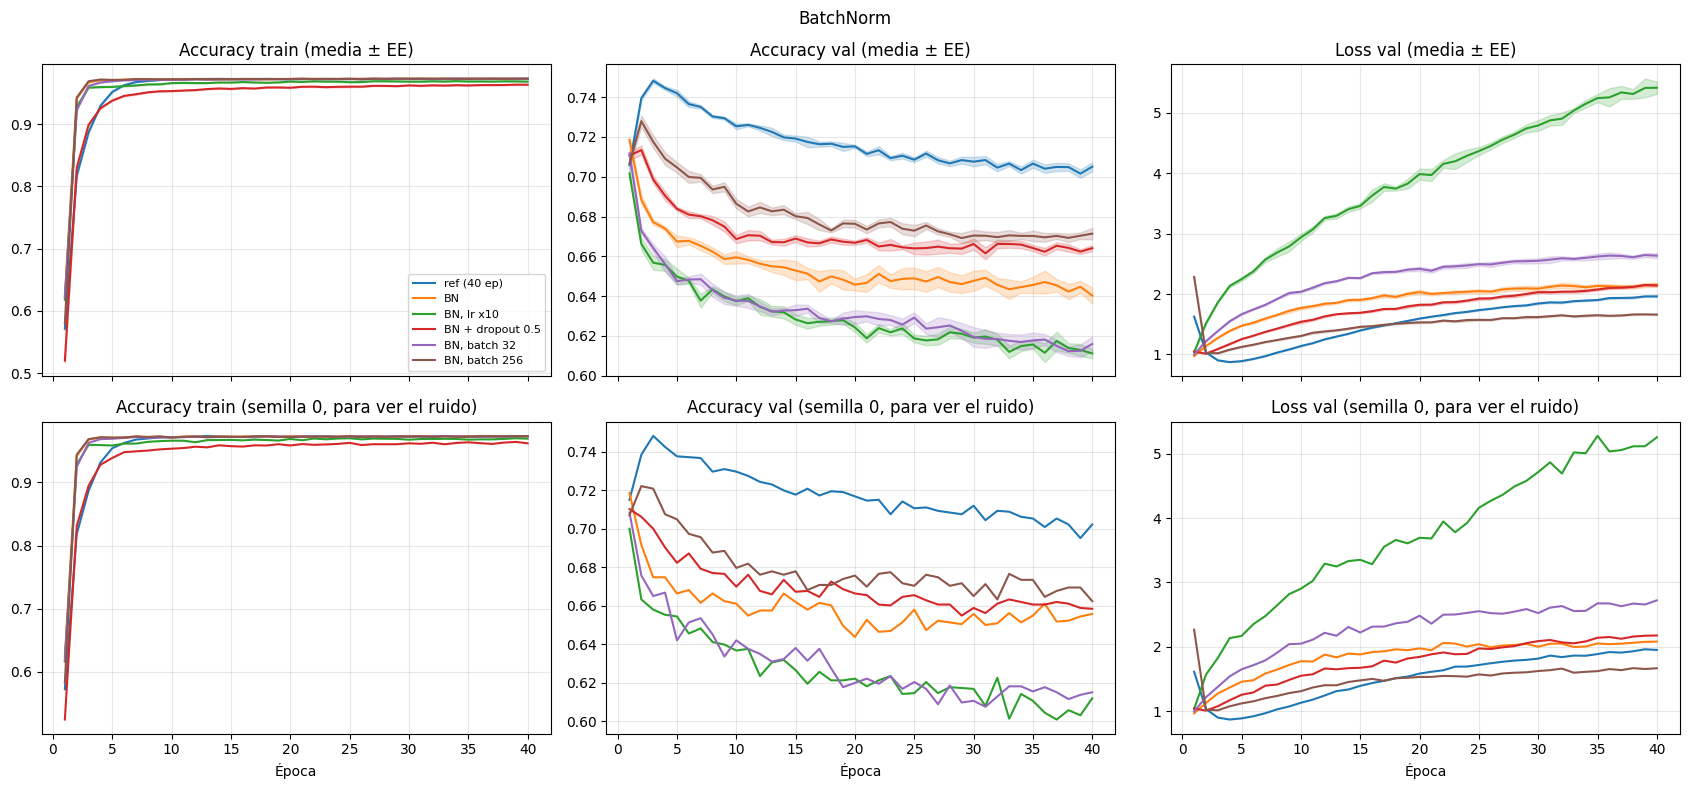

In [ ]:
import matplotlib.pyplot as plt

def plot_group(names, title):
    keys = [("train_acc", "Accuracy train"), ("val_acc", "Accuracy val"), ("val_loss", "Loss val")]
    fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
    for name in names:
        runs = RESULTS[name]["runs"]
        for j, (k, lab) in enumerate(keys):
            Y = np.array([r["history"][k] for r in runs]); x = np.arange(1, Y.shape[1] + 1)
            m, se = Y.mean(0), Y.std(0, ddof=1) / np.sqrt(len(Y))
            line, = axes[0][j].plot(x, m, label=name)
            axes[0][j].fill_between(x, m - se, m + se, alpha=0.2, color=line.get_color())
            axes[1][j].plot(x, Y[0], color=line.get_color(), label=name)
    for j, (k, lab) in enumerate(keys):
        axes[0][j].set_title(f"{lab} (media ± EE)"); axes[1][j].set_title(f"{lab} (semilla 0, para ver el ruido)")
        axes[1][j].set_xlabel("Época")
        for i in range(2):
            axes[i][j].grid(alpha=0.3)
    axes[0][0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

GRUPOS = {
    "L2 (λ creciente)": ["ref (sin reg)", "L2 1e-05", "L2 1e-04", "L2 1e-03"],
    "L1 y L1+L2": ["ref (sin reg)", "L1 1e-06", "L1 1e-05", "L1 1e-04", "L1 1e-5 + L2 1e-4"],
    "Dropout y max-norm": ["ref (40 ep)", "dropout 0.2", "dropout 0.5", "dropout 0.5 + maxnorm 4"],
    "Learning rate": ["ref (40 ep)", "ref, lr x10", "dropout 0.5", "dropout 0.5, lr x3", "dropout 0.5, lr x10"],
    "BatchNorm": ["ref (40 ep)", "BN", "BN, lr x10", "BN + dropout 0.5", "BN, batch 32", "BN, batch 256"],
}
for titulo, nombres in GRUPOS.items():
    plot_group(nombres, titulo)

**8. Valores absolutos de pesos**

In [ ]:
def speed_table(names, thr=0.70):
    rows = []
    for name in names:
        runs = RESULTS[name]["runs"]
        eps, ts, vmax, emax, n_ok = [], [], [], [], 0
        for run in runs:
            h = run["history"]; va = np.array(h["val_acc"]); et = np.cumsum(h["epoch_time"])
            vmax.append(va.max()); emax.append(int(va.argmax()) + 1)
            hit = np.where(va >= thr)[0]
            if len(hit):
                n_ok += 1; eps.append(hit[0] + 1); ts.append(et[hit[0]])
        rows.append({"config": name, f"alcanzan_{thr}": f"{n_ok}/{len(runs)}",
                     "epocas_hasta_thr": np.mean(eps) if eps else np.nan,
                     "seg_hasta_thr": np.mean(ts) if ts else np.nan,
                     "val_acc_max": np.mean(vmax), "epoca_del_max": np.median(emax),
                     "seg_por_epoca": np.mean([np.median(r["history"]["epoch_time"]) for r in runs])})
    return pd.DataFrame(rows).round(3)

print(speed_table(list(RESULTS.keys())).to_string(index=False))

                 config alcanzan_0.7  epocas_hasta_thr  seg_hasta_thr  val_acc_max  epoca_del_max  seg_por_epoca
          ref (sin reg)          5/5               1.4          0.772        0.749            3.0          0.552
               L2 1e-05          5/5               1.4          0.836        0.744            3.0          0.602
               L2 1e-04          5/5               1.6          0.994        0.732            3.0          0.594
               L2 1e-03          5/5              10.6          6.447        0.710           19.0          0.597
               L1 1e-06          5/5               1.4          0.852        0.742            3.0          0.589
               L1 1e-05          5/5               2.0          1.246        0.724            3.0          0.593
               L1 1e-04          0/5               NaN            NaN        0.668           24.0          0.594
      L1 1e-5 + L2 1e-4          5/5               2.0          1.353        0.716            4.

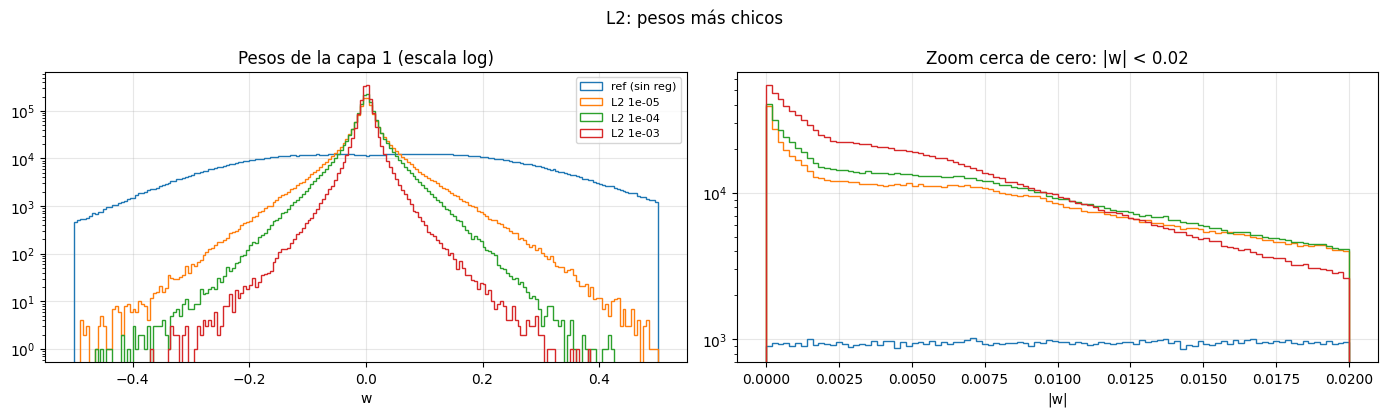

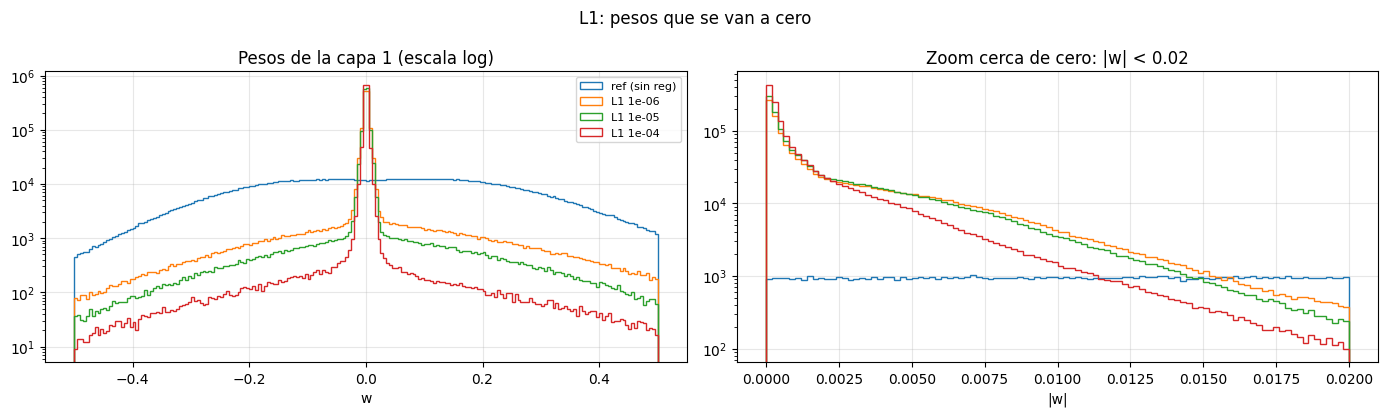

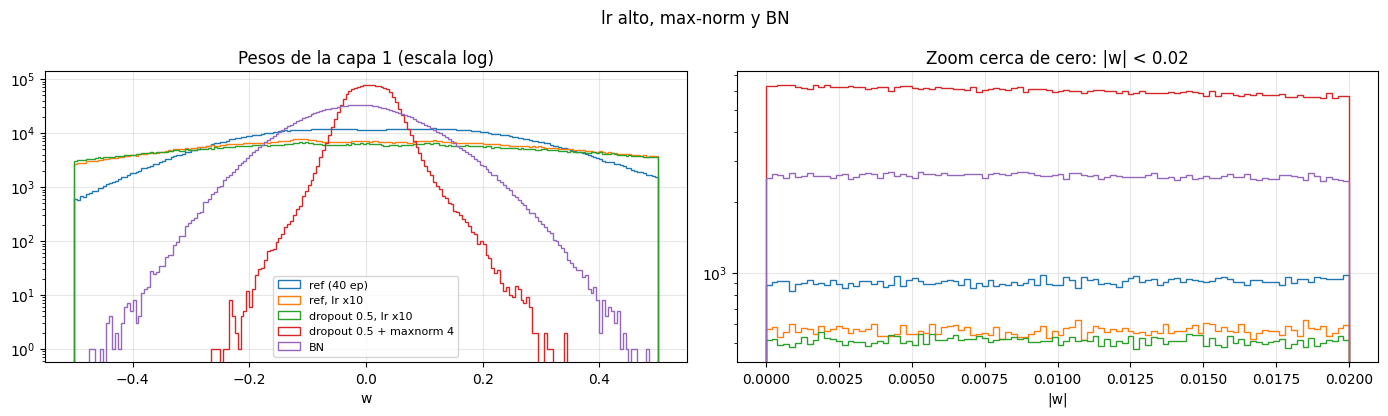

                 config  |w|_medio  |w|_max  norma_max_neurona  frac<1e-4  frac<1e-3  frac<1e-2
          ref (sin reg)     0.1775   1.4862          25.991400     0.0003     0.0031     0.0315
               L2 1e-05     0.0279   0.6570           6.395800     0.0150     0.0846     0.4241
               L2 1e-04     0.0197   0.5239           4.432800     0.0147     0.0970     0.4939
               L2 1e-03     0.0101   0.3843           2.653400     0.0189     0.1485     0.6959
               L1 1e-06     0.0218   1.3464          10.973900     0.0974     0.4232     0.8434
               L1 1e-05     0.0114   1.2076           7.889600     0.1094     0.4826     0.9056
               L1 1e-04     0.0041   1.5008           6.180800     0.1577     0.6471     0.9674
      L1 1e-5 + L2 1e-4     0.0122   0.6001           4.604400     0.0605     0.3045     0.7679
            ref (40 ep)     0.1856   1.5613          27.640900     0.0003     0.0030     0.0303
            dropout 0.2     0.1778   1.7

In [ ]:
def weight_table(names):
    rows = []
    for n in names:
        w = RESULTS[n]["runs"][0]["w_first_layer"]; a = np.abs(w)
        W = w.reshape(BASE["hidden"][0], -1)               # (neuronas, features)
        rows.append({"config": n, "|w|_medio": a.mean(), "|w|_max": a.max(),
                     "norma_max_neurona": np.linalg.norm(W, axis=1).max(),
                     "frac<1e-4": (a < 1e-4).mean(), "frac<1e-3": (a < 1e-3).mean(), "frac<1e-2": (a < 1e-2).mean()})
    return pd.DataFrame(rows).round(4)

def plot_weight_hist(names, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    for n in names:
        w = RESULTS[n]["runs"][0]["w_first_layer"]
        ax[0].hist(w, bins=200, range=(-0.5, 0.5), histtype="step", log=True, label=n)
        ax[1].hist(np.abs(w), bins=100, range=(0, 0.02), histtype="step", log=True, label=n)
    ax[0].set_title("Pesos de la capa 1 (escala log)"); ax[1].set_title("Zoom cerca de cero: |w| < 0.02")
    ax[0].set_xlabel("w"); ax[1].set_xlabel("|w|"); ax[0].legend(fontsize=8)
    for a_ in ax: a_.grid(alpha=0.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()

W_GRUPOS = {
    "L2: pesos más chicos": ["ref (sin reg)", "L2 1e-05", "L2 1e-04", "L2 1e-03"],
    "L1: pesos que se van a cero": ["ref (sin reg)", "L1 1e-06", "L1 1e-05", "L1 1e-04"],
    "lr alto, max-norm y BN": ["ref (40 ep)", "ref, lr x10", "dropout 0.5, lr x10", "dropout 0.5 + maxnorm 4", "BN"],
}
for t, nombres in W_GRUPOS.items():
    plot_weight_hist(nombres, t)
print(weight_table(list(RESULTS.keys())).to_string(index=False))

**Análisis:**

Es importante aclarar que los histogramas y la tabla corresponden a la primera capa al final del entrenamiento (épocas 30 o 40) y *no a la mejor época*.

En el modelo *sin regularizar*, se ve cómo el peso medio crece a la par del sobreajuste, arrancando en ~0.011 y terminando en 0.1775. En cambio, aplicar L2 achica todo y castiga a los pesos grandes, ya que la norma máxima por neurona bajó de 26 a un rango de 2.65 a 6.40. Por su parte, L1 dispersa los pesos, logrando que hasta el 97% quede por debajo de 0.01, aunque deja sobrevivir a unos pocos pesos con valores máximos cercanos a 1.5.

Por otro lado, respecto a *Max-norm*, la restricción se activa bien limitando la norma a 4.00, y comprobamos que al subir el lr ×10 el peso medio se multiplica por 1.9 a 2.8.

Con *BatchNorm* se puede apreciar que los pesos se mantienen bajos, pero si le aumentamos el lr, crecen mucho. Se asume que esto pasa porque BatchNorm es invariante a la escala, permitiendo que los pesos "se inflen" sin alterar el resultado final de la capa.

Todo esto coincide con el documento de clase, ya que los pesos crecen cuando el modelo sobreajusta *(página 27)*, L2 penaliza más a los pesos grandes *(página 52)*, L1 deja pocos pesos grandes y anula el resto *(página 58)*, un lr alto agranda la escala de los histogramas de pesos *(página 68)* y el max-norm acota la norma por neurona *(página 71)*. Con Adam los pesos penalizados con L1 no llegan a cero exacto: solo entre el 10% y el 16% quedan por debajo de 1e-4.

**9. Tiempos, lr y ruido**

In [ ]:
def conv_table(names, thr=0.95):
    rows = []
    for name in names:
        runs = RESULTS[name]["runs"]; eps, ts, ok = [], [], 0
        for run in runs:
            h = run["history"]; ta = np.array(h["train_acc"]); et = np.cumsum(h["epoch_time"])
            hit = np.where(ta >= thr)[0]
            if len(hit):
                ok += 1; eps.append(hit[0] + 1); ts.append(et[hit[0]])
        rows.append({"config": name, f"train_acc>={thr}": f"{ok}/{len(runs)}",
                     "epocas": np.mean(eps) if eps else np.nan, "seg": np.mean(ts) if ts else np.nan})
    return pd.DataFrame(rows).round(2)

print(conv_table(list(RESULTS.keys())).to_string(index=False))

                 config train_acc>=0.95  epocas   seg
          ref (sin reg)             5/5     5.0  2.77
               L2 1e-05             5/5     6.0  3.74
               L2 1e-04             5/5     9.4  5.70
               L2 1e-03             0/5     NaN   NaN
               L1 1e-06             5/5     6.0  3.64
               L1 1e-05             5/5     9.4  5.75
               L1 1e-04             0/5     NaN   NaN
      L1 1e-5 + L2 1e-4             5/5    19.2 12.83
            ref (40 ep)             5/5     5.0  2.81
            dropout 0.2             5/5     6.8  3.92
            dropout 0.5             5/5    10.8  6.22
dropout 0.5 + maxnorm 4             0/5     NaN   NaN
     dropout 0.5, lr x3             5/5     6.0  3.47
    dropout 0.5, lr x10             5/5     5.0  2.93
            ref, lr x10             5/5     3.0  1.73
                     BN             5/5     3.0  1.75
             BN, lr x10             5/5     3.0  1.77
       BN + dropout 0.5     

**Análisis:**

- **Tiempo por época**: Se tiene una reproducibilidad casi perfecta, ya que hay < 1% de variación. Las penalizaciones L1 y L2 suman entre 7% y 10% de tiempo extra por el recálculo sobre los 1.5 millones de pesos, y aproximadamente el 18% cuando se combinan (L1+L2: 0.651 contra 0.552 s por época). El resto de las técnicas (Dropout, max-norm, BN) impactan alrededor del 6% o menos. El factor determinante es el batch size ya que, con BatchNorm, pasar de un batch de 32 a uno de 256 reduce el tiempo de 0.875 a 0.333 segundos.

- **Convergencia**: Tomando como meta un train_acc ≥ 0.95, el modelo base necesita 5 épocas. BatchNorm, o un lr ×10 por separado, acelera el proceso a 3 épocas *(página 78 del apunte teórico de clase)*. En cambio, Dropout 0.5 retrasa la convergencia a 10.8 épocas *(página 68 del apunte teórico de clase)*, a menos que se compense subiendo el lr. Las regularizaciones fuertes (L2 1e-3, L1 1e-4, o Dropout + max-norm) directamente impiden que el modelo alcance ese 0.95 porque limitan demasiado el ajuste. El umbral de convergencia lo definí sobre train_acc ≥ 0.95. Primero probé con val_acc ≥ 0.70, pero casi todos los modelos lo alcanzan en 1 o 2 épocas y no permite comparar. Cambié el criterio después de ver esos resultados y lo dejo declarado.

- **Learning rate**: En la etapa de búsqueda, SGD exigió un learning rate 12 veces mayor que Adam y 16 veces mayor que RMSprop. En los experimentos, confirmamos que aumentar el lr acelera la convergencia pero tiene como contra que castiga el pico de accuracy de validación (sección 7).

- **Ruido**: El ruido absoluto es bajo. En validación, L2 en 1e-3 lo duplica, y un lr ×10 (sin BN) lo multiplica por 2.7. Se puede observar que BatchNorm aumentó el ruido a 0.0033, contradiciendo lo visto en la *página 82 del apunte teórico de clase*. En entrenamiento, Dropout 0.5 lo casi duplica (0.0013 contra 0.0007), pero Dropout+max-norm lo triplica (0.0024) y L2 1e-3 también (0.0022).

**10. Modelo final**

La configuración se decide **por validación y se declara antes de ver el test**: Dropout 0.5 sobre la base (mayor val_acc medio entre las pruebas, 0.7464) con 6 épocas, la mediana de la mejor época. Se entrena con el split de entrenamiento y se monitorea en validación. El test se evalúa **una vez por modelo**, con 5 semillas.

In [ ]:
FINAL = dict(dropout=0.5, epochs=6)
cfg = {**BASE, **FINAL}

_, test_texts_final = preprocessed_cache[(BASE["remove_stopwords"], BASE["normalization"])]
X_a_chk, X_te, _ = vectorize_data(a, test_texts_final, BASE["ngram"], BASE["max_features"], BASE["min_df"])  # fit solo con train
assert X_a_chk.shape == X_a.shape
test_loader_final = DataLoader(to_tensor_dataset(X_te, newsgroups_test.target), batch_size=cfg["batch_size"], shuffle=False)
print(f"Vectores vacíos -> train: {(X_a.getnnz(axis=1) == 0).mean():.2%} | test: {(X_te.getnnz(axis=1) == 0).mean():.2%}")

@torch.no_grad()
def test_accuracy(m, loader):
    m.eval(); ok = n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        ok += (m(xb).argmax(1) == yb).sum().item(); n += xb.size(0)
    return ok / n

finals, test_accs, val_accs = [], [], []
for s in range(5):
    torch.manual_seed(2000 + s); np.random.seed(2000 + s)
    tl = DataLoader(DS_TR, batch_size=cfg["batch_size"], shuffle=True, drop_last=True)
    vl = DataLoader(DS_VA, batch_size=cfg["batch_size"], shuffle=False)
    m = MLP(N_FEATURES, cfg["hidden"], NUM_CLASSES, cfg["activation"], dropout=cfg["dropout"], batchnorm=cfg["batchnorm"]).to(device)
    opt = optim.Adam(m.parameters(), lr=cfg["lr"], betas=cfg["betas"])
    h = train_model(m, tl, vl, opt, epochs=cfg["epochs"], l1=cfg["l1"], l2=cfg["l2"], max_norm=cfg["max_norm"] or None)
    finals.append(h); val_accs.append(h["val_acc"][-1])
    test_accs.append(test_accuracy(m, test_loader_final))     # test: una sola evaluación por modelo
    model = m                                                 # lo usan las celdas de la sección 11

se = lambda v: np.std(v, ddof=1) / np.sqrt(len(v))
print(f"val_acc (época {cfg['epochs']}): {np.mean(val_accs):.4f} ± {se(val_accs):.4f}")
print(f"test_acc: {np.mean(test_accs):.4f} ± {se(test_accs):.4f} | por semilla: {np.round(test_accs, 4)}")
print(f"tiempo de entrenamiento por modelo: {np.mean([sum(h['epoch_time']) for h in finals]):.1f} s")

Vectores vacíos -> train: 2.87% | test: 3.24%
val_acc (época 6): 0.7457 ± 0.0011
test_acc: 0.6857 ± 0.0013 | por semilla: [0.6899 0.6857 0.682  0.6864 0.6843]
tiempo de entrenamiento por modelo: 3.6 s


In [ ]:
from torch.utils.tensorboard import SummaryWriter
if mlflow.active_run(): mlflow.end_run()
mlflow.set_experiment("tp3_regularizacion")
with mlflow.start_run(run_name="final_dropout0.5"):
    mlflow.log_params({k: str(v) for k, v in cfg.items()})
    writer = SummaryWriter(log_dir="runs/tp3_final"); h0 = finals[0]
    for ep in range(len(h0["val_acc"])):
        writer.add_scalars("loss", {"train": h0["train_loss"][ep], "val": h0["val_loss"][ep]}, ep)
        writer.add_scalars("accuracy", {"train": h0["train_acc"][ep], "val": h0["val_acc"][ep]}, ep)
        mlflow.log_metrics({"train_loss": h0["train_loss"][ep], "val_loss": h0["val_loss"][ep],
                            "train_acc": h0["train_acc"][ep], "val_acc": h0["val_acc"][ep]}, step=ep)
    mlflow.log_metric("test_acc_mean", float(np.mean(test_accs))); mlflow.log_metric("test_acc_se", float(se(test_accs)))
    writer.close()

2026/11/10 11:32:34 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 11:32:34 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 11:32:36 INFO mlflow.tracking.fluent: Experiment with name 'tp3_regularizacion' does not exist. Creating a new experiment.


**Análisis:**

La configuración final (Dropout 0.5 sobre la base, 6 épocas) se eligió por validación antes de mirar el test. Con 5 semillas, el val_acc en la época 6 fue 0.7457 ± 0.0011 y el test 0.6857 ± 0.0013 (entre 0.6820 y 0.6899), con 3.6 s de entrenamiento por modelo. La caída de ~6 puntos entre validación y test se explica en parte porque la validación es un split aleatorio del train y el test es el split oficial por fecha, más difícil, y en parte porque la configuración se eligió sobre la validación. El 2.87% de los documentos de train y el 3.24% de los de test tienen vector TF-IDF vacío, por lo que no se pueden clasificar mejor que al azar. Como referencia, el MLP del TP2 dio 0.6808 en test (una semilla, entrenado con todo el train) y el softmax del TP1 0.6569. Sin embargo, la comparación no es directa ya que cambian la configuración y el protocolo utilizados.


**11. Evaluación Final**

In [ ]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

Accuracy en test: 0.6843

                          precision    recall  f1-score   support

             alt.atheism       0.53      0.50      0.52       319
           comp.graphics       0.57      0.66      0.61       389
 comp.os.ms-windows.misc       0.62      0.56      0.59       394
comp.sys.ibm.pc.hardware       0.66      0.61      0.63       392
   comp.sys.mac.hardware       0.70      0.71      0.70       385
          comp.windows.x       0.77      0.69      0.73       395
            misc.forsale       0.75      0.78      0.76       390
               rec.autos       0.73      0.67      0.70       396
         rec.motorcycles       0.49      0.77      0.60       398
      rec.sport.baseball       0.91      0.83      0.87       397
        rec.sport.hockey       0.92      0.89      0.90       399
               sci.crypt       0.84      0.70      0.76       396
         sci.electronics       0.57      0.60      0.58       393
                 sci.med       0.79      0.75    

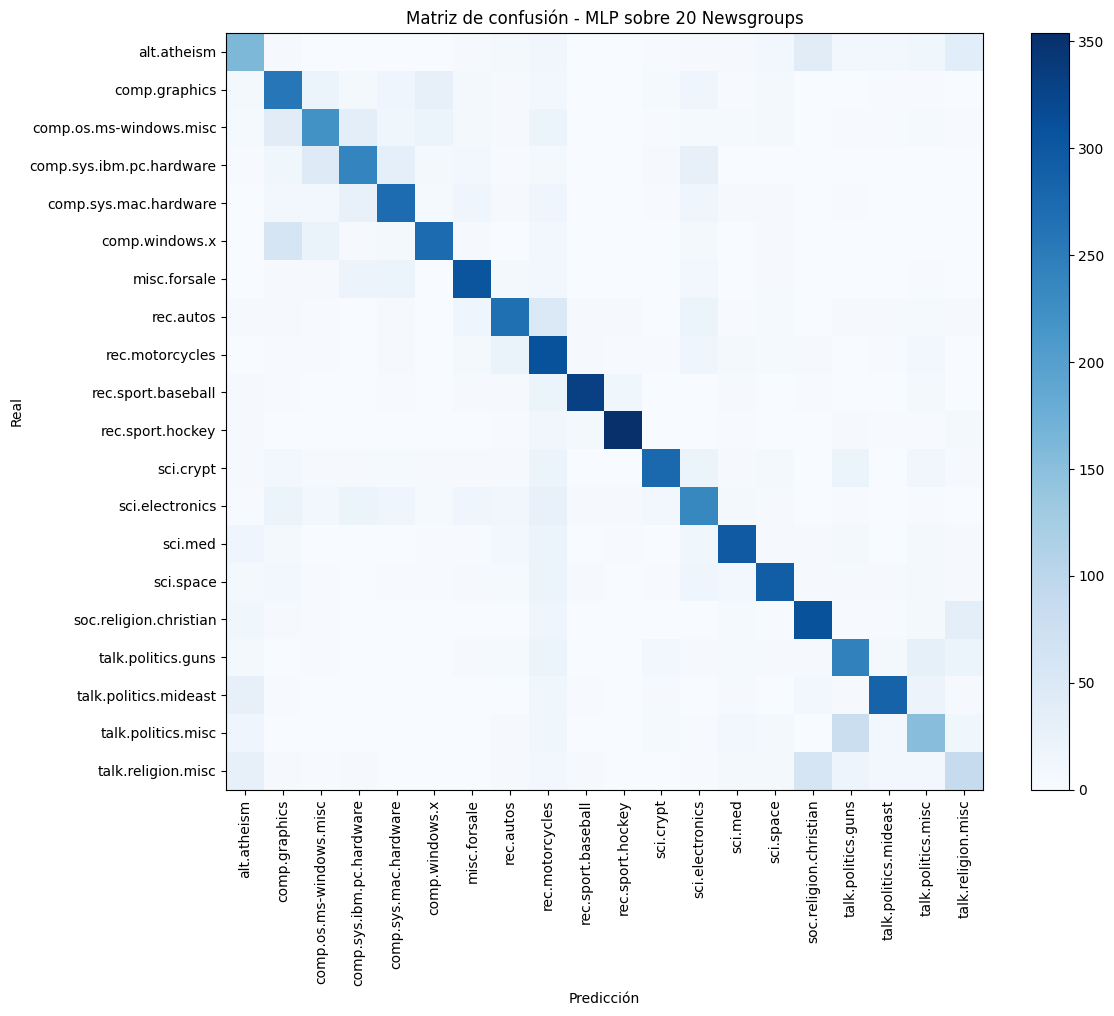

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout()
plt.show()

**Análisis:**

El reporte y la matriz corresponden al modelo de la semilla 4 (accuracy 0.68), que se vuelve a evaluar sin usarlo para decidir nada. Las clases con peor f1 son `talk.religion.misc` (0.36), `talk.politics.misc` (0.50) y `alt.atheism` (0.52), igual que en el TP1 y el TP2. Por otro lado, las mejores son `rec.sport.hockey` (0.90) y `rec.sport.baseball` (0.87).

Se puede observar como `rec.motorcycles` absorbe errores (precisión 0.49, recall 0.77), igual que en el TP2 (precisión 0.47), mientras que en el TP1 fue `rec.autos`.

Como referencia, el MLP del TP2 dio 0.6808 en test (una semilla, entrenado con todo el train) y el softmax del TP1 0.6569. Sin embargo, nuevamente hay que aclarar que la comparación no es directa, ya que cambian la configuración y el protocolo utilizados.


**12. Análisis y conclusiones**

**Conclusiones:**

- En este setup particular (usando TF-IDF con unos 9.000 documentos y una sola capa oculta), se vio que ninguna técnica "hace magia" para romper el techo. Con esto me refiero a que, con early stopping, todas las configuraciones terminaron chocando contra un accuracy máximo de ~0.749 en validación.

- Lo que **sí** hacen Dropout y max-norm es **estabilizar el modelo**: no suben ese techo, pero evitan que el rendimiento caiga si se entrena de más. Por ejemplo, en la época 40 el modelo con Dropout 0.5 + max-norm queda en ≈0.743, mientras que el modelo base baja a ≈0.705 (valores leídos de las curvas).

- Se comprobó que **L1** y **L2** hacen exactamente lo que dice la teoría *(L2 achica los pesos y L1 los dispersa)*, pero en la práctica nos jugaron en contra, ya que con un λ de 1e-5 o mayor, disminuye el accuracy y hacen que el modelo tarde más en converger.

- Por otro lado, **BatchNorm** y un **learning rate** mayor aceleran el entrenamiento (train_acc ≥ 0.95 en 3 épocas contra 5), **pero el modelo sobreajusta más rápido y el rendimiento final es peor**.

- Al final del proyecto, la *búsqueda automática* terminó eligiendo quedarse solo con **Dropout 0.5** y prácticamente anuló la regularización explícita (dejó el λ casi en cero).

- El modelo final (Dropout 0.5, 6 épocas, 5 semillas) llegó a **0.6857 ± 0.0013 en test**, contra **0.7457 en validación**.

---



**Limitaciones:**

- **Usamos un solo split de train/validación**, por lo que el* error estándar solo está midiendo qué tanto varían los resultados al cambiar la semilla, no al cambiar los datos*.

- Los histogramas de los pesos son una "foto" súper específica, ya que los sacamos de una sola semilla y a la época final, por lo que hay que observarlos con el cuidado correspondiente.

- No se llegaron a probar la estandarización de la entrada ni a usar ReduceLROnPlateau.

- Cuando teníamos lambdas muy grandes, algunos entrenamientos quedaron truncos porque las 30 épocas no les alcanzaron para converger.

- Se elegieron la "mejor época" basándonos en el mínimo de val_loss. Si se hubiera cortado por el máximo de val_acc, es probable que el ranking de las mejores configuraciones cambiara un poco.

- En la búsqueda, alpha de RMSprop se muestreó de forma uniforme en [0.8, 0.999] y no se exploró el momentum de RMSprop. Habría sido mejor muestrear 1 − alpha en escala logarítmica.

- La métrica de la búsqueda es la accuracy de validación en la época de mínimo val_loss. Como se elige el mejor entre muchos trials sobre la misma validación, sobreestima el desempeño esperado. Esta es la razón por la que el test queda más bajo.

- La comparación con los TP1 y TP2 no es directa, ya que cambian la configuración y el protocolo utilizados.